# Baseline de churn — Regressão Logística

Neste notebook treinamos um primeiro classificador para identificar clientes que cancelam. O teste fica reservado para a avaliação final: o pré-processamento é ajustado dentro do pipeline durante a validação cruzada e, depois, somente no conjunto de treino completo. As métricas do teste não serão usadas para selecionar o modelo.

## 1. Carregar e preparar os dados

O caminho do CSV é relativo à pasta `notebooks`. Convertemos `TotalCharges` em número, removemos `customerID` por ser um identificador e codificamos `Churn` como 0 para `No` e 1 para `Yes`. Fixamos a semente para tornar as etapas aleatórias reproduzíveis.

In [1]:
RANDOM_STATE = 42

import json
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

np.random.seed(RANDOM_STATE)

df = pd.read_csv("../data/telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
y = df["Churn"].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("A coluna Churn contém valores fora das categorias No/Yes.")

X = df.drop(columns=["customerID", "Churn"])
print(f"Dimensões dos dados: {df.shape}")
print(f"Valores ausentes em TotalCharges após conversão: {X['TotalCharges'].isna().sum()}")
print(f"Clientes com churn: {int(y.sum())} ({y.mean():.2%})")
display(X.head())

Dimensões dos dados: (7043, 21)
Valores ausentes em TotalCharges após conversão: 11
Clientes com churn: 1869 (26.54%)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


## 2. Separar treino e teste

Reservamos 20% dos registros para o teste final. A estratificação mantém a proporção de churn aproximadamente igual nos dois grupos. O conjunto de teste não será usado na validação cruzada nem para ajustar o pré-processamento.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Treino: {len(X_train)} linhas; proporção de churn: {y_train.mean():.2%}")
print(f"Teste: {len(X_test)} linhas; proporção de churn: {y_test.mean():.2%}")

Treino: 5634 linhas; proporção de churn: 26.54%
Teste: 1409 linhas; proporção de churn: 26.54%


## 3. Pipeline e validação cruzada no treino

O `ColumnTransformer` imputa a mediana e padroniza as colunas numéricas. Para as colunas categóricas, aplica one-hot encoding e ignora categorias inéditas. Todas as transformações estão dentro do `Pipeline`, portanto são ajustadas separadamente em cada partição de treino da validação cruzada. Calculamos média e desvio-padrão de F1, AUC-ROC, precisão e recall para churn.

In [3]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = OneHotEncoder(handle_unknown="ignore")
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, make_column_selector(dtype_include="number")),
        (
            "categorical",
            categorical_pipeline,
            make_column_selector(dtype_exclude="number"),
        ),
    ]
)

baseline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        ),
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "f1": "f1",
    "auc": "roc_auc",
    "precision": "precision",
    "recall": "recall",
}

training_start = time.perf_counter()
cv_results = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise",
)

cv_metrics = {}
for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    cv_metrics[f"{metric}_media"] = scores.mean()
    cv_metrics[f"{metric}_dp"] = scores.std(ddof=1)

cv_summary = pd.DataFrame(
    {
        "métrica": ["F1 (churn)", "AUC-ROC", "Precisão (churn)", "Recall (churn)"],
        "média": [cv_metrics["f1_media"], cv_metrics["auc_media"], cv_metrics["precision_media"], cv_metrics["recall_media"]],
        "desvio-padrão": [cv_metrics["f1_dp"], cv_metrics["auc_dp"], cv_metrics["precision_dp"], cv_metrics["recall_dp"]],
    }
)
display(cv_summary.round(4))

fit_start = time.perf_counter()
baseline.fit(X_train, y_train)
final_fit_seconds = time.perf_counter() - fit_start
training_seconds = time.perf_counter() - training_start
print(f"Pipeline ajustado no treino completo em {final_fit_seconds:.2f} s.")
print(f"Tempo total de validação cruzada e ajuste final: {training_seconds:.2f} s.")

Pipeline ajustado no treino completo em 0.06 s.
Tempo total de validação cruzada e ajuste final: 0.85 s.


,métrica,média,desvio-padrão
0,F1 (churn),0.5923,0.0331
1,AUC-ROC,0.8461,0.0140
2,Precisão (churn),0.6529,0.0285
3,Recall (churn),0.5431,0.0460


## 4. Avaliação final no teste

Após concluir a validação cruzada e ajustar o pipeline no treino completo, avaliamos o teste uma única vez. O limiar de classificação é o padrão de 0,5. A AUC-ROC usa probabilidades; F1, precisão e recall consideram churn como a classe positiva.

Relatório de classificação:
              precision    recall  f1-score   support

   Não churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Matriz de confusão:


,valor
f1_teste,0.6040
auc_teste,0.8419
precisao_teste,0.6572
recall_teste,0.5588
acuracia_teste,0.8055


,Previsto: não churn,Previsto: churn
Real: não churn,926,109
Real: churn,165,209


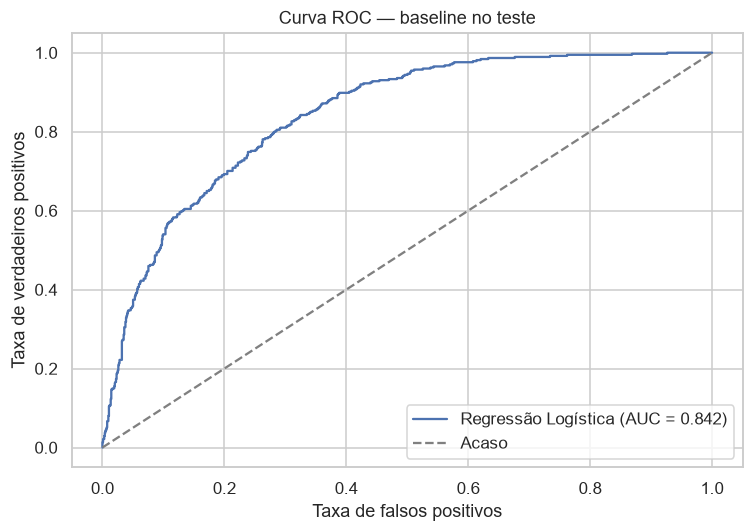

In [4]:
y_pred = baseline.predict(X_test)
y_proba = baseline.predict_proba(X_test)[:, 1]

test_metrics = {
    "f1_teste": f1_score(y_test, y_pred, pos_label=1),
    "auc_teste": roc_auc_score(y_test, y_proba),
    "precisao_teste": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "recall_teste": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "acuracia_teste": (y_pred == y_test).mean(),
}
display(pd.Series(test_metrics, name="valor").to_frame().round(4))

print("Relatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Não churn", "Churn"],
        zero_division=0,
    )
)

confusion = confusion_matrix(y_test, y_pred, labels=[0, 1])
confusion_df = pd.DataFrame(
    confusion,
    index=["Real: não churn", "Real: churn"],
    columns=["Previsto: não churn", "Previsto: churn"],
)
print("Matriz de confusão:")
display(confusion_df)

false_positive_rate, true_positive_rate, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(7, 5))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"Regressão Logística (AUC = {test_metrics['auc_teste']:.3f})",
)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acaso")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC — baseline no teste")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Referência: classificador que sempre prevê não churn

Como a classe majoritária é `No`, comparamos o baseline com um classificador simples que sempre prevê não churn. Essa referência mostra por que a acurácia, sozinha, pode parecer razoável mesmo quando nenhum cliente em risco é identificado.

In [5]:
dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_metrics = {
    "acurácia": (dummy_pred == y_test).mean(),
    "F1 (churn)": f1_score(y_test, dummy_pred, pos_label=1, zero_division=0),
    "precisão (churn)": precision_score(y_test, dummy_pred, pos_label=1, zero_division=0),
    "recall (churn)": recall_score(y_test, dummy_pred, pos_label=1, zero_division=0),
}
comparison = pd.DataFrame(
    [
        {"modelo": "Regressão Logística", "acurácia": test_metrics["acuracia_teste"], "F1 (churn)": test_metrics["f1_teste"], "precisão (churn)": test_metrics["precisao_teste"], "recall (churn)": test_metrics["recall_teste"]},
        {"modelo": "Sempre não churn", **dummy_metrics},
    ]
)
display(comparison.set_index("modelo").round(4))

,acurácia,F1 (churn),precisão (churn),recall (churn)
modelo,,,,
Regressão Logística,0.8055,0.604,0.6572,0.5588
Sempre não churn,0.7346,0.000,0.0000,0.0000


## 6. Registrar o experimento

Salvamos uma linha com a configuração, as métricas médias da validação cruzada, o tempo medido e as métricas do teste. Reexecutar o notebook atualiza a linha deste baseline em vez de duplicá-la.

In [6]:
experiment_columns = [
    "experimento",
    "modelo",
    "parametros",
    "f1_cv_media",
    "f1_cv_dp",
    "auc_cv_media",
    "auc_cv_dp",
    "precisao_cv",
    "recall_cv",
    "tempo_treino_s",
    "f1_teste",
    "auc_teste",
    "data",
]
experiment_row = {
    "experimento": "baseline_logistic_regression",
    "modelo": "LogisticRegression",
    "parametros": json.dumps(
        {
            "max_iter": 1000,
            "random_state": RANDOM_STATE,
            "test_size": 0.2,
            "cv_folds": 5,
            "cv_shuffle": True,
        },
        sort_keys=True,
    ),
    "f1_cv_media": cv_metrics["f1_media"],
    "f1_cv_dp": cv_metrics["f1_dp"],
    "auc_cv_media": cv_metrics["auc_media"],
    "auc_cv_dp": cv_metrics["auc_dp"],
    "precisao_cv": cv_metrics["precision_media"],
    "recall_cv": cv_metrics["recall_media"],
    "tempo_treino_s": training_seconds,
    "f1_teste": test_metrics["f1_teste"],
    "auc_teste": test_metrics["auc_teste"],
    "data": date.today().isoformat(),
}

experiments_path = Path("../docs/experimentos.csv")
if experiments_path.exists():
    experiments_df = pd.read_csv(experiments_path)
    if list(experiments_df.columns) != experiment_columns:
        raise ValueError("O cabeçalho existente em docs/experimentos.csv não corresponde ao formato esperado.")
    experiments_df = experiments_df.loc[
        experiments_df["experimento"] != experiment_row["experimento"]
    ]
    experiments_df = pd.concat(
        [experiments_df, pd.DataFrame([experiment_row])], ignore_index=True
    )
else:
    experiments_df = pd.DataFrame([experiment_row], columns=experiment_columns)
experiments_df.to_csv(experiments_path, index=False)

print(f"Experimento registrado em {experiments_path}:")
display(experiments_df.tail(1).T)

Experimento registrado em ..\docs\experimentos.csv:


,0
experimento,baseline_logistic_regression
modelo,LogisticRegression
parametros,"{""cv_folds"": 5, ""cv_shuffle"": true, ""max_iter"": 1000, ""random_state"": 42, ""test_size"": 0.2}"
f1_cv_media,0.592316
f1_cv_dp,0.033108
auc_cv_media,0.846137
auc_cv_dp,0.014026
precisao_cv,0.652899
recall_cv,0.543144
tempo_treino_s,0.851838


## 7. Conclusões e próximos passos

As métricas a seguir são calculadas nas células acima e ficam registradas em `docs/experimentos.csv`.

| Métrica | Validação cruzada no treino | Teste final |
|---|---:|---:|
| F1 (churn) | 0,5923 ± 0,0331 | 0,6040 |
| AUC-ROC | 0,8461 ± 0,0140 | 0,8419 |
| Precisão (churn) | 0,6529 ± 0,0285 | 0,6572 |
| Recall (churn) | 0,5431 ± 0,0460 | 0,5588 |

**Referência majoritária no teste:** o classificador que sempre prevê não churn obteve acurácia de 0,7346, mas F1, precisão e recall de churn iguais a 0. A Regressão Logística alcançou F1 de 0,6040 e recall de 0,5588, mostrando que encontra clientes em risco, embora ainda deixe parte deles sem identificação.

**Pontos fracos:** a Regressão Logística é um modelo linear e pode não representar relações mais complexas. No teste, houve 165 falsos negativos entre 374 clientes que cancelaram. O limiar padrão de 0,5 pode deixar de encontrar parte dos clientes em risco; a avaliação final foi feita em uma única divisão.

**Próximos passos:** na Etapa 2, comparar este baseline com Random Forest e MLP usando a mesma divisão e validação cruzada estratificada. A escolha será feita pelas métricas de validação cruzada, sem reutilizar o conjunto de teste para selecionar modelos ou hiperparâmetros.